# XGBoost for Regression

- We will use the below small dataset to demonstrate how to use XGBoost for regression tasks. 

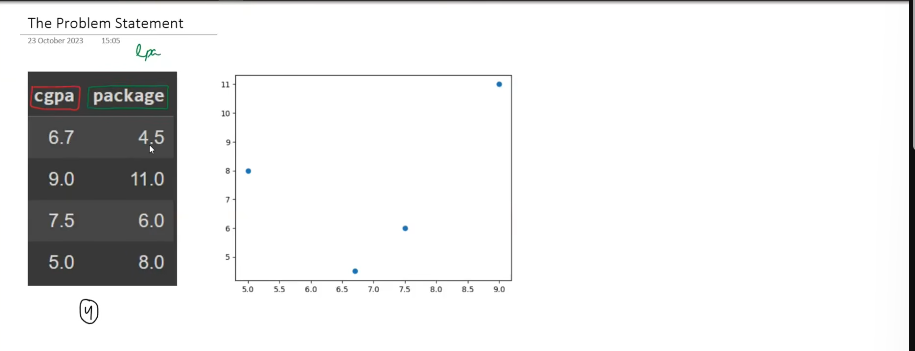

1 feature: cgpa
target: package

# Solution Overview

- As XGBoost is ultimately a gradient boosting algorithm, just optimized for speed, performance and flexibility

- So steps of using XGBoost for regression are similar to any other gradient boosting algorithm.

### Stage 1: Using 1st model as Mean Model

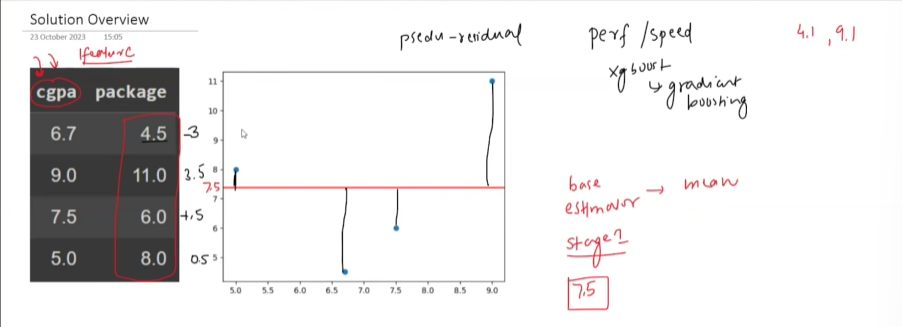

### Stage 2: Using 2nd model as Decision Tree Model

- Take input data as cgpa and target as the residual calculated from the 1st model.
- So we are trying to predict the residuals/pseudo-residuals 

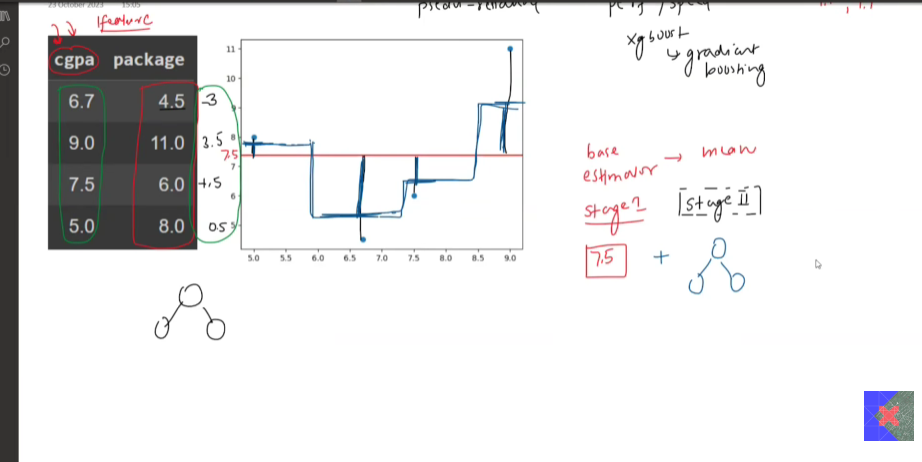

- Similarly we can keep adding more models and keep predicting the residuals from the previous model.
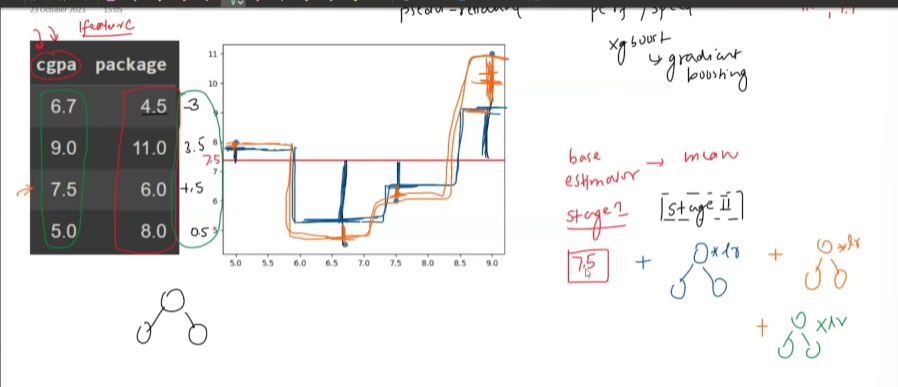

- Now the above flow is of Gradient Boosting Algorithm, and XGBoost will also follow the same flow, but it have one **major difference**:
    - **Difference**: <text style="color:cyan">The desicion tree built in XGBoost is not built using regular gini impurity or entropy, but it is built using a different criteria which we will discuss in the next section.</text>





- To understand the difference, let's see the step by step calculation of all the stages we discussed above.

### Stage 1: Using 1st model as Mean Model

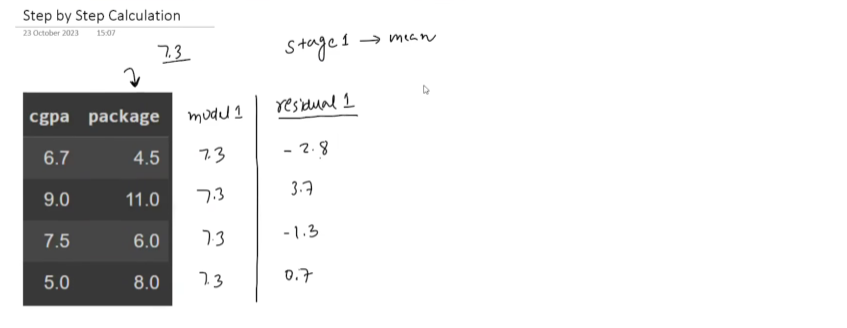

### Stage 2: Using 2nd model as Decision Tree Model

- So here before building the decision tree, we take all the residual in a leaf node and calculate **Similarity Score** for the leaf node. The similarity score is calculated using the below formula:

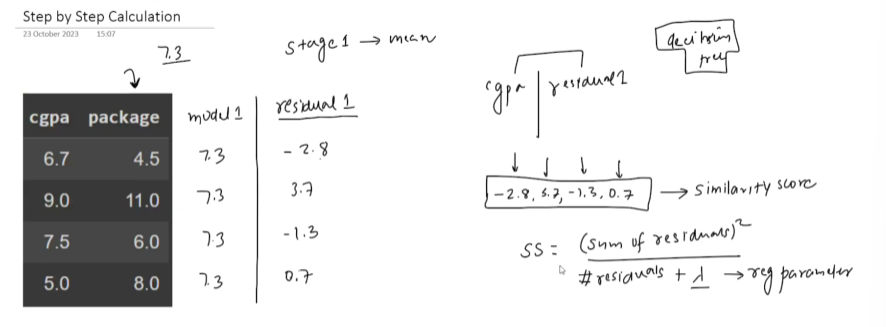

- For simplicity, we are taking $\lambda = 0$

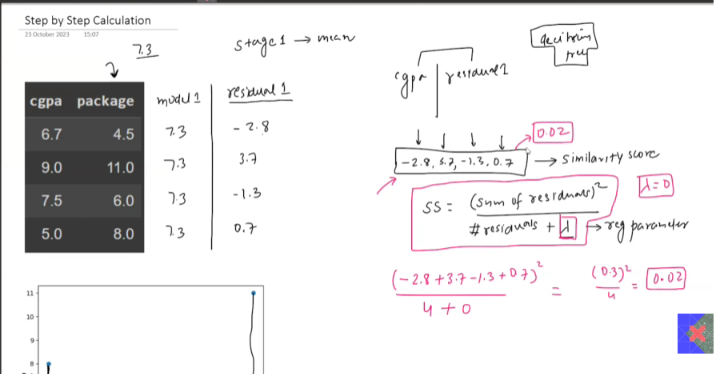

- Now we will try to slit the residuals in the leaf node into two child nodes, and we will calculate the similarity score for both the child nodes using the same formula. ANd see if we can increase the similarity score by splitting the leaf node into two child nodes.

- The splitting will be based on the feature cgpa, and the condition of spilt will be detirmined the same way as we do in normal decision tree just here instead of judging by highest Information Gain, we will judge by the highest similarity score.

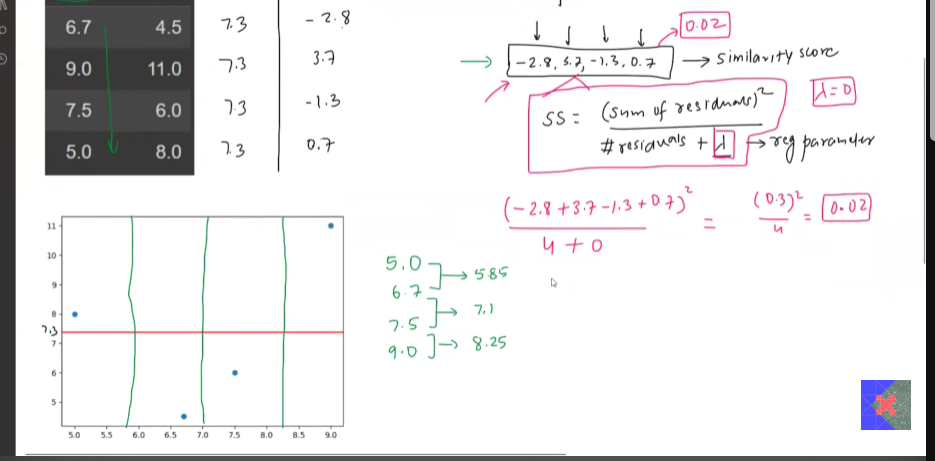

- In the above pic, we have sorted the cgpa values in ascending order, and we will try to split the leaf node at each possible cgpa value and calculate the similarity score for both child nodes.

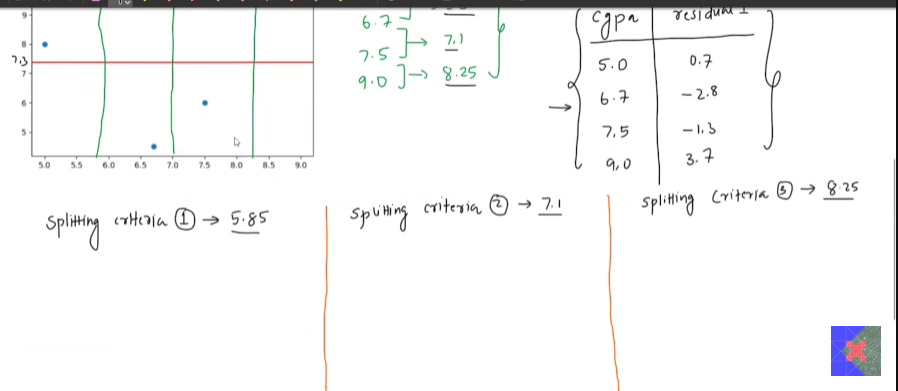

- Now to judge the gain in similarity score after splitting, we will calculate the gain in similarity score using the below formula:

$$ Gain = Similarity_{left} + Similarity_{right} - Similarity_{parent} $$

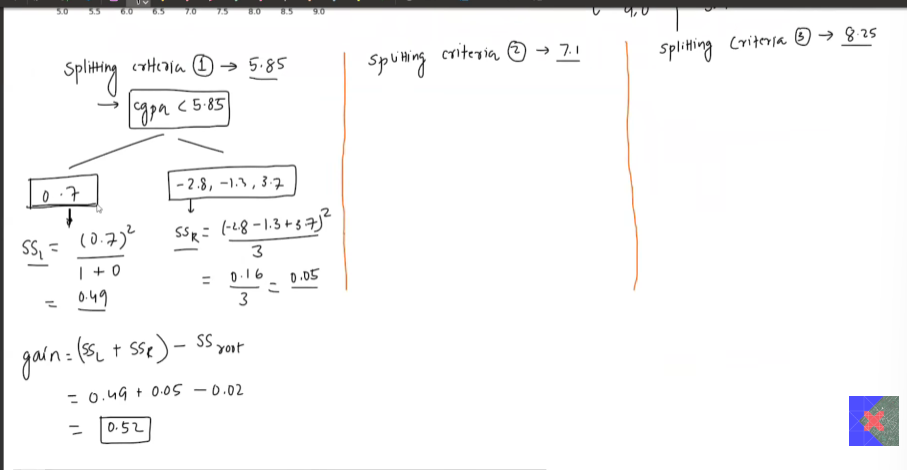

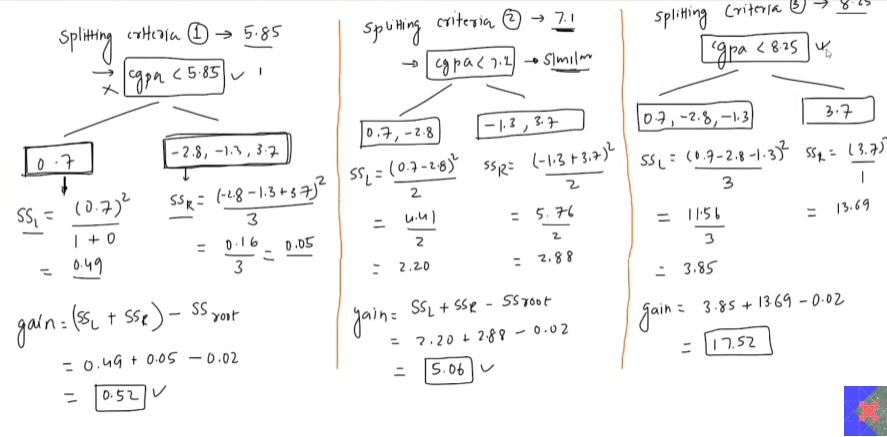

- So you can see that the highest gain in similarity score is at cgpa = 8.25, so we will split the leaf node at cgpa = 8.25 and create two child nodes.

- **Conclusion**: So in stage 2, the desicon tree we are building will have root node with criteria cgpa <= 8.25 

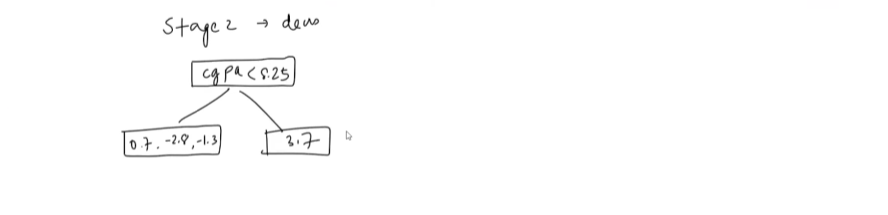

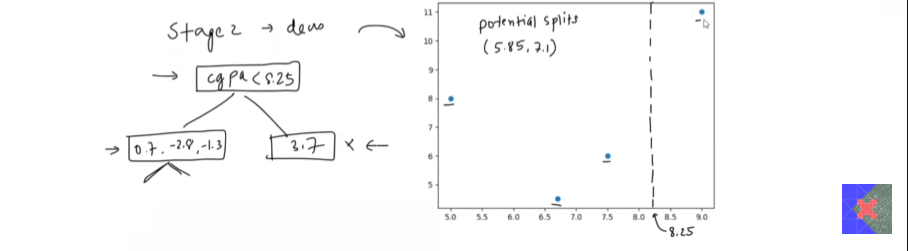

- Now on the left child node, we further have 2 slit conditions, and we will calculate the similarity score for both the child nodes and see if we can increase the similarity score by splitting the left child node into two child nodes. And if yes, we will split the left child node into two child nodes

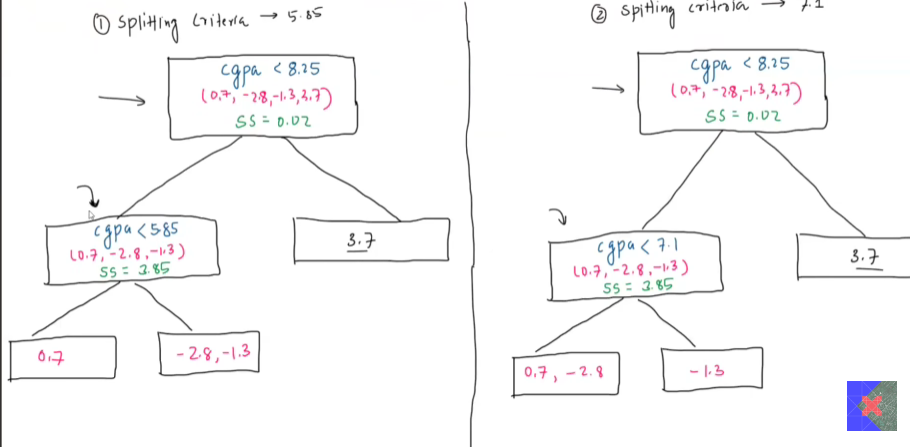

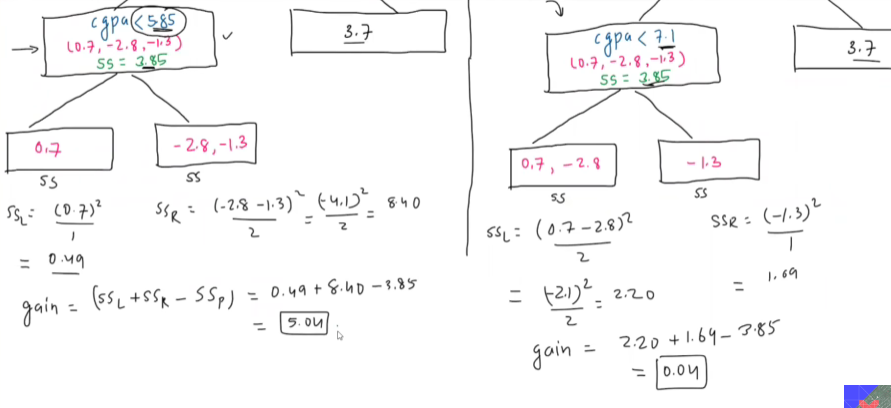

- So, below is the final desicion tree keeping max depth as 2 

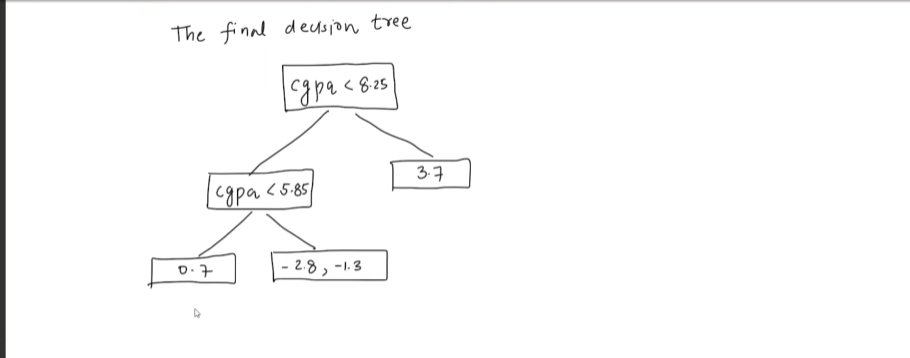

<text style="color:cyan">THough in XGBoost the default max depth is 6, we are keeping it as 2 to avoid overfitting.</text>

#### Calculating output at each leaf node:

- Since this desicion tree is built differently than a normal decision tree, the output at each leaf node is also calculated differently. The output at each leaf node is calculated using the below formula:

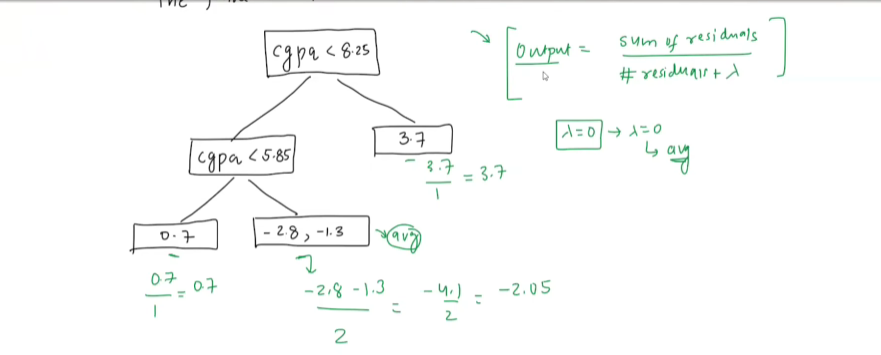

- If $$\lambda = 0$$, then the output at each leaf node is ultimately the mean of the residuals in that leaf node.

- So finally for each sample, we will calculate the output of the 2nd model using the above decision tree and add it to the output of the 1st model to get the final output. and also calulate the residuals for the 3rd model.

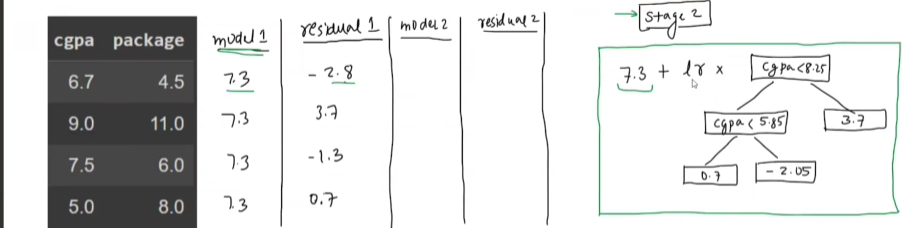

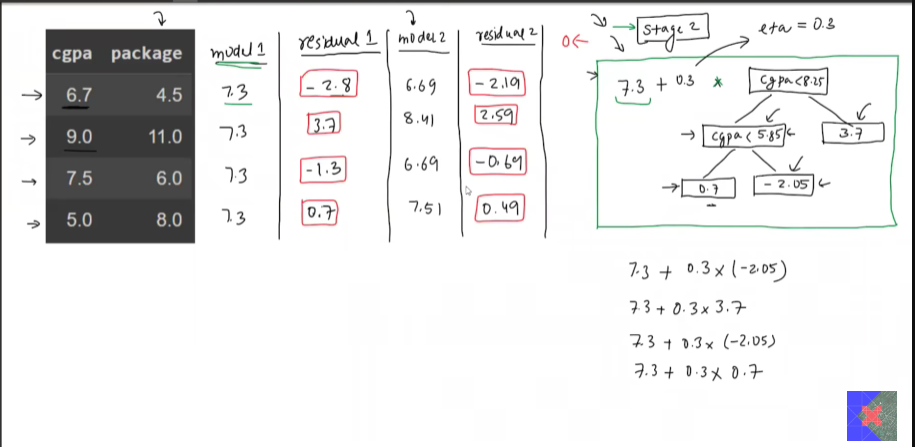

- As you can see the residuals are decreasing with each model, which means our combned model is performing better than the mean (stage 1) model. And we can keep adding more models to further reduce the residuals and improve the performance of the combined model.

### Stage 3: Using 3rd model as Decision Tree Model
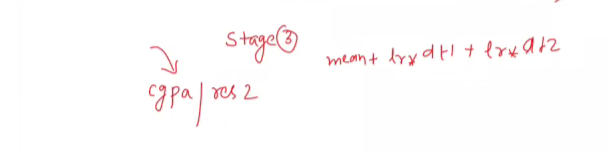

- Similarly we can keep adding more models and reach the final model which is a combination of all the models we have built so far. And this final model will be our XGBoost model for regression.

# For multiple features, how to build the decision tree in XGBoost?

- Similar steps will be followed for multiple features as well, but the only difference is that we will have to consider all the features while calculating the similarity score and gain in similarity score for each possible split. And we will choose the split which gives us the highest gain in similarity score among all the features. Just like we do in normal decision tree, we will consider all the features and all the possible split conditions for each feature and choose the best split condition which gives us the highest gain in similarity score.

# Two different algorithms for building decision tree in XGBoost

1. **Exact Greedy Algorithm**: This is the default algorithm used in XGBoost for building decision tree. In this algorithm, we will consider all the possible split conditions for each feature and choose the best split condition which gives us the highest gain in similarity score. This algorithm is very accurate but it is also very slow and not suitable for large datasets. (this is the one we have discussed so far)

2. **Approximate Algorithm**: This algorithm is used for large datasets where the exact greedy algorithm is too slow. In this algorithm, we will not consider all the possible split conditions for each feature, but we will consider only a subset of them. (Will study later)

- For smaller datasets, we can use the exact greedy algorithm, but for larger datasets, we will have to use the approximate algorithm to build the decision tree in XGBoost.